# PANDAS


What is Pandas?
* Pandas is a fast, powerful, flexible and easy to use open source data analysis and manipulation tool, built on top of the Python programming language.

## Pandas Series
A Pandas Series is like a column in a table. It is a 1-D array holding data of any type.

In [54]:
import numpy as np
import pandas as pd

In [55]:
# string
country = ['India','Pakistan','USA','Nepal','Srilanka']

pd.Series(country)

0       India
1    Pakistan
2         USA
3       Nepal
4    Srilanka
dtype: str

In [56]:
# integers
runs = [13,24,56,78,100]
pd.Series(runs)

0     13
1     24
2     56
3     78
4    100
dtype: int64

In [172]:
# custom index
marks = [67,57,89,100]
subjects = ['maths','english','science','hindi']


marks=pd.Series(marks,index=subjects)
print(marks)

maths       67
english     57
science     89
hindi      100
dtype: int64


#### SERIES FROM A DICTIONARY

In [165]:
marks = {
    'maths':67,
    'english':57,
    'science':89,
    'hindi':100
}

marks_series = pd.Series(marks,name='students marks')
marks_series

maths       67
english     57
science     89
hindi      100
Name: students marks, dtype: int64

In [58]:
# setting a name
marks = pd.Series(marks,index=subjects,name='student marks')
print(marks)
# when converting it to dataframe it automaticaly names the header of the table to name earlier provided 
marks.to_frame()

maths       67
english     57
science     89
hindi      100
Name: student marks, dtype: int64


,student marks
maths,67
english,57
science,89
hindi,100


### SERIES ATTRIBUTES

In [60]:
# size
marks_series.size

4

In [61]:
# dtype
marks_series.dtype

dtype('int64')

In [62]:
# name
marks_series.name


'student marks'

In [63]:
# is_unique
marks_series.is_unique

pd.Series([1,1,2,3,4,5]).is_unique

False

In [64]:
# index
marks_series.index

Index(['maths', 'english', 'science', 'hindi'], dtype='str')

In [65]:
# values
marks_series.values

array([ 67,  57,  89, 100])

## SERIES USING READ CSV

### USING subs.csv DATASET

In [82]:
# with one column 
print(type(pd.read_csv("DATASETS/subs.csv"))) # this  gives dataframe

# Read the CSV and immediately squeeze it into a Series
subs = pd.read_csv("DATASETS/subs.csv").squeeze("columns")
print(subs)
print(type(subs))

<class 'pandas.DataFrame'>
0       48
1       57
2       40
3       43
4       44
      ... 
360    231
361    226
362    155
363    144
364    172
Name: subs gained, Length: 365, dtype: int64
<class 'pandas.Series'>


### USING kohli_ipl.csv  DATASET

In [209]:
runs=pd.read_csv("DATASETS/kohli_ipl.csv",index_col='match_no').squeeze('columns')
print(runs)
print(type(runs))

match_no
1       1
2      23
3      13
4      12
5       1
       ..
211     0
212    20
213    73
214    25
215     7
Name: runs, Length: 215, dtype: int64
<class 'pandas.Series'>


### USING bollywood.csv DATASETS

In [68]:
movies = pd.read_csv('DATASETS/bollywood.csv',index_col='movie').squeeze("columns")
movies

movie
Uri: The Surgical Strike                   Vicky Kaushal
Battalion 609                                Vicky Ahuja
The Accidental Prime Minister (film)         Anupam Kher
Why Cheat India                            Emraan Hashmi
Evening Shadows                         Mona Ambegaonkar
                                              ...       
Hum Tumhare Hain Sanam                    Shah Rukh Khan
Aankhen (2002 film)                     Amitabh Bachchan
Saathiya (film)                             Vivek Oberoi
Company (film)                                Ajay Devgn
Awara Paagal Deewana                        Akshay Kumar
Name: lead, Length: 1500, dtype: str

### HEAD AND TAIL METHOD

In [69]:
# getting top 5 rows 
subs.head()

0    48
1    57
2    40
3    43
4    44
Name: subs gained, dtype: int64

In [70]:
# getting any desired no. of rows 
runs.head(3)

match_no
1     1
2    23
3    13
Name: runs, dtype: int64

In [71]:
# tail gets us element from the last
runs.tail()

match_no
211     0
212    20
213    73
214    25
215     7
Name: runs, dtype: int64

### SAMPLE

In [72]:
# GETS US ONE ROW RANDOMLY 
movies.sample()

movie
Paan Singh Tomar (film)    Irrfan Khan
Name: lead, dtype: str

### VALUE COUNTS

In [73]:
# value_counts -> movies
movies.value_counts()

lead
Akshay Kumar        48
Amitabh Bachchan    45
Ajay Devgn          38
Salman Khan         31
Sanjay Dutt         26
                    ..
Tanishaa Mukerji     1
Tanuja               1
Ankit                1
Rakhee Gulzar        1
Edwin Fernandes      1
Name: count, Length: 566, dtype: int64

### SORT VALUES

In [74]:
runs.sort_values()

match_no
8        0
87       0
93       0
91       0
206      0
      ... 
164    100
120    100
123    108
126    109
128    113
Name: runs, Length: 215, dtype: int64

In [75]:
runs.sort_values(ascending=False)

match_no
128    113
126    109
123    108
120    100
164    100
      ... 
93       0
130      0
206      0
207      0
211      0
Name: runs, Length: 215, dtype: int64

In [76]:
# sort_values -> inplace
runs.sort_values(ascending=False).head(1).values[0]
# it  does not change the values permanently but if we want to do so we can do by using inplace=true

np.int64(113)

In [77]:
# sort_index -> inplace
movies.sort_index()
# sorts index character wise 

movie
1920 (film)                   Rajniesh Duggall
1920: London                     Sharman Joshi
1920: The Evil Returns             Vicky Ahuja
1971 (2007 film)                Manoj Bajpayee
2 States (2014 film)              Arjun Kapoor
                                   ...        
Zindagi 50-50                      Veena Malik
Zindagi Na Milegi Dobara        Hrithik Roshan
Zindagi Tere Naam           Mithun Chakraborty
Zokkomon                       Darsheel Safary
Zor Lagaa Ke...Haiya!            Meghan Jadhav
Name: lead, Length: 1500, dtype: str

## SERIES MATHS METHODS 

#### count()

In [78]:
# count
# The series.count() method in Pandas counts the total number of non-missing (non-null) values in your Series.
runs.count()
# this gives 215 ,when their are  no null values 

np.int64(215)

In [79]:
# added  a null value 
runs.loc[216]=np.nan
runs.loc[217]=None


In [80]:
# ran the method againa but it still gives 215 
runs.count()

np.int64(215)

In [81]:
# size give the totol lentgh  irrespective of the values are none/null/nan
runs.size

217

#### sum()

In [83]:
# gives total sum of the object in the series
subs.sum()

np.int64(49510)

#### STATISTICAL SUMMARY

In [85]:
print(subs.mean())
print(subs.median())
print(subs.mode())
print(subs.std())
print(subs.var())

135.64383561643837
123.0
0    105
Name: subs gained, dtype: int64
62.6750230372527
3928.1585127201565


#### min()/max()

In [86]:
print(runs.max())
print(runs.min())

113.0
0.0


#### describe()

In [87]:
# describe the statistical summary of the given series data 
runs.describe()

count    215.000000
mean      30.855814
std       26.229801
min        0.000000
25%        9.000000
50%       24.000000
75%       48.000000
max      113.000000
Name: runs, dtype: float64

## SERIES INDEXING

In a Pandas Series, indexing works differently depending on whether your index labels are numbers or strings.

 Label-Based Indexing vs. Position-Based Indexing

Every Pandas Series has two layers of indexing running at the same time:
1. The Label Index: The custom names you give the rows (e.g., 'match_no', movie titles, or explicit numbers). You access this using .loc[].
2. The Positional Index: The hidden, automatic integer positions starting from 0 to len-1. You access this using .iloc[].


#### POSITIVE INDEXING 


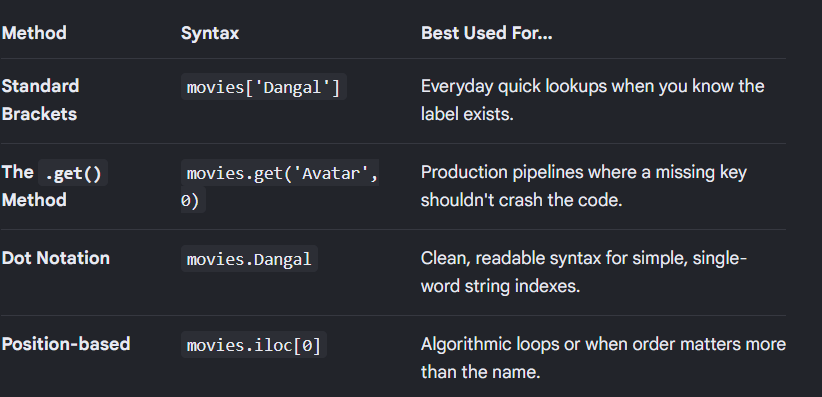

In [88]:
movies

movie
Uri: The Surgical Strike                   Vicky Kaushal
Battalion 609                                Vicky Ahuja
The Accidental Prime Minister (film)         Anupam Kher
Why Cheat India                            Emraan Hashmi
Evening Shadows                         Mona Ambegaonkar
                                              ...       
Hum Tumhare Hain Sanam                    Shah Rukh Khan
Aankhen (2002 film)                     Amitabh Bachchan
Saathiya (film)                             Vivek Oberoi
Company (film)                                Ajay Devgn
Awara Paagal Deewana                        Akshay Kumar
Name: lead, Length: 1500, dtype: str

In [93]:
print(movies.iloc[0])
print(movies['Awara Paagal Deewana'])
print(movies.get("Dangal",0))

Vicky Kaushal
Akshay Kumar
0



The Golden Rules of Series Indexing

* Rule 1: If your index uses Strings, using a negative number like series[-1] works out of the box because Pandas defaults to positions.
* Rule 2: If your index uses Numbers, series[-1] will search for a label named -1 and likely crash.
* Rule 3 (Best Practice): Never leave it to guesswork. Always use .loc[] when you want to filter by explicit names/labels, and always use .iloc[] when you are doing math with positions or using negative numbers like [-1].

#### NEGATIVE INDEXING
Because the explicit labels are strings, Python knows that a number like -1 must refer to the position.
* movies[-1] => 150 (Returns the last item safely)
* movies.iloc[-1] => 150 (The explicit, safer way to write it)


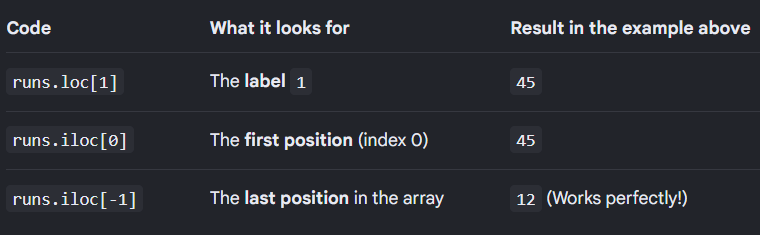

## SERIES SLICING 

 The rules for where a slice stops and how negative numbers behave change completely depending on whether you are using .loc (labels) or .iloc (positions).

The Golden Rule of Slicing Boundaries

* .iloc (Position-based) is EXCLUSIVE: It works exactly like standard Python lists. The stop boundary is not included.
* .loc (Label-based) is INCLUSIVE: Because it uses names, Pandas includes the stop boundary so you don't have to guess what comes next.

 

In [95]:
# .iloc does not include the last element 
runs.iloc[2:4]


match_no
3    13.0
4    12.0
Name: runs, dtype: float64

In [ ]:
# last element is included in .loc
runs.loc[2:4]

match_no
2    23.0
3    13.0
4    12.0
Name: runs, dtype: float64


### String-Based Indexing (e.g., Movie Names)

Let's assume a movies Series where the index labels are strings:
['Dangal', 'Sholay', 'Lagaan', 'Bajrangi', 'PK']

#### 1. Positive Slicing

* .iloc[0:3] (Positions 0, 1, 2): Grabs from position 0 up to, but excluding, position 3.
	* Result: Dangal, Sholay, Lagaan
* .loc['Dangal':'Lagaan'] (Labels): Grabs everything from 'Dangal' up to and including 'Lagaan'.
	* Result: Dangal, Sholay, Lagaan


#### 2. Negative Slicing

* .iloc[-3:] (Last 3 items): Starts 3 positions from the end and goes to the very end.
	* Result: Lagaan, Bajrangi, PK
* .loc[-3:] ❌ CRASHES: It searches for a literal text string named "-3". Since no movie is named "-3", it throws a KeyError.
	* Note: You cannot use negative integers to step backward inside .loc when your index consists of strings.


### Numerical Indexing (e.g., Match Numbers)

Let's assume a runs Series where the index labels are explicit match numbers:
[101, 102, 103, 104, 105] (Notice it does not start at 0).

#### 1. Positive Slicing

* .iloc[0:3] (Positions 0, 1, 2): Looks strictly at physical memory positions. It grabs the first 3 rows.
	* Result: Matches 101, 102, 103
* .loc[101:103] (Labels): Looks at the actual numbers printed on the labels. It grabs everything from label 101 up to and including label 103.
	* Result: Matches 101, 102, 103
* ⚠️ Warning: Writing .loc[0:3] here will return an empty Series or crash because there are no labels named 0, 1, 2, or 3.

#### 2. Negative Slicing

* .iloc[:-2] (Excluding the last two rows): Grabs everything from the start position up to, but excluding, the second-to-last item.
	* Result: Matches 101, 102, 103
* .loc[:-2] ❌ CRASHES: Just like with strings, it goes searching for an actual row label named -2. Because your matches are labeled 101 to 105, it cannot find a label named -2 and throws a KeyError.


### NOT USING .loc or .iloc

#### 1. Direct Slicing with Numbers (Positive & Negative)

If you pass numbers into a direct slice, Pandas completely ignores your index labels and acts exactly like a standard Python list (.iloc behavior). This is true even if your index labels are numbers themselves.
* Boundary Rule: The stop index is exclusive.
* Negative Slicing: It works perfectly to count backward from the end.

#### 2. Direct Slicing with Strings

If you pass string labels into a direct slice, Pandas switches context and treats it like a label-based lookup (.loc behavior).
* Boundary Rule: The stop label is inclusive.
* Negative Slicing: Passing a negative number like series[-2:] will still fall back to positional list slicing (last 2 rows). However, passing a string like series['-2':'PK'] will try to look for a label named "-2" and fail.


In [116]:
# direct slicing eith the strings 

# what if we use directly without using .loc() or .iloc() ,like we do with list 
# works the same way as .iloc
# for the series which have number index
print(runs[1:3])
print(runs[-2:])

match_no
2    23.0
3    13.0
Name: runs, dtype: float64
match_no
216   NaN
217   NaN
Name: runs, dtype: float64


In [113]:
# for the series which have string as index 
print(movies[:3])
print('\n')
print(movies[-2:])

movie
Uri: The Surgical Strike                Vicky Kaushal
Battalion 609                             Vicky Ahuja
The Accidental Prime Minister (film)      Anupam Kher
Name: lead, dtype: str


movie
Company (film)            Ajay Devgn
Awara Paagal Deewana    Akshay Kumar
Name: lead, dtype: str


In [114]:
movies

movie
Uri: The Surgical Strike                   Vicky Kaushal
Battalion 609                                Vicky Ahuja
The Accidental Prime Minister (film)         Anupam Kher
Why Cheat India                            Emraan Hashmi
Evening Shadows                         Mona Ambegaonkar
                                              ...       
Hum Tumhare Hain Sanam                    Shah Rukh Khan
Aankhen (2002 film)                     Amitabh Bachchan
Saathiya (film)                             Vivek Oberoi
Company (film)                                Ajay Devgn
Awara Paagal Deewana                        Akshay Kumar
Name: lead, Length: 1500, dtype: str

In [ ]:
# direct slicing with strings
# both the ends are includedin the results 
print(movies["Battalion 609":"Evening Shadows"])

movie
Battalion 609                                Vicky Ahuja
The Accidental Prime Minister (film)         Anupam Kher
Why Cheat India                            Emraan Hashmi
Evening Shadows                         Mona Ambegaonkar
Name: lead, dtype: str


In [119]:
# works fine with just one parameter 
movies[:"Evening Shadows"]

movie
Uri: The Surgical Strike                   Vicky Kaushal
Battalion 609                                Vicky Ahuja
The Accidental Prime Minister (film)         Anupam Kher
Why Cheat India                            Emraan Hashmi
Evening Shadows                         Mona Ambegaonkar
Name: lead, dtype: str

## FANCY INDEXING 

In [ ]:
# if we want to work with indexes we have to  use iloc
movies.iloc[[1,2,5]]

movie
Battalion 609                                    Vicky Ahuja
The Accidental Prime Minister (film)             Anupam Kher
Soni (film)                             Geetika Vidya Ohlyan
Name: lead, dtype: str

In [129]:
# fancy indexing with labels as strings
movies[["Uri: The Surgical Strike",'Why Cheat India',"Soni (film)"]]

movie
Uri: The Surgical Strike           Vicky Kaushal
Why Cheat India                    Emraan Hashmi
Soni (film)                 Geetika Vidya Ohlyan
Name: lead, dtype: str

In [128]:
print(runs[[1,2,4]]) # this search for the given label in the series 
print(runs.iloc[[1,2,4]]) # this search for the index position given in the list

match_no
1     1.0
2    23.0
4    12.0
Name: runs, dtype: float64
match_no
2    23.0
3    13.0
5     1.0
Name: runs, dtype: float64


## EDITING SERIES 

In [156]:
marks

maths       67
english     57
science     89
hindi      100
dtype: int64

In [ ]:
# we have to do it using .iloc as the direct assignment doesn't work like older version
# we we try to do it using direct index position a new element is created  
marks.iloc[1]=100

In [158]:
marks

maths       67
english    100
science     89
hindi      100
dtype: int64

In [166]:
marks_series

maths       67
english     57
science     89
hindi      100
Name: students marks, dtype: int64

In [167]:
marks_series.iloc[1]=100
print(marks_series)

maths       67
english    100
science     89
hindi      100
Name: students marks, dtype: int64


In [168]:
# what if we don't have a given value we have to it by directly assign a value to the desired index 
marks_series["computer"]=100


In [169]:
marks_series

maths        67
english     100
science      89
hindi       100
computer    100
Name: students marks, dtype: int64

In [173]:
# assigning values through the slicing 
marks[0:3]=0

In [174]:
marks

maths        0
english      0
science      0
hindi      100
dtype: int64

In [176]:
# we can also change the values through the fancy indexing 
marks.iloc[[1,2,3]]=[100,89,90]

In [ ]:
marks

maths        0
english    100
science     89
hindi       90
dtype: int64

In [178]:
# we can also use labels directly 
marks["maths"]=100

In [179]:
marks

maths      100
english    100
science     89
hindi       90
dtype: int64

## SERIES WITH PYHTON FUCNTIONALITY 

### len/type/dir/sorted/max/min

In [ ]:
# len/type/dir/sorted/max/min
print(len(subs))
print(type(subs))
print(dir(subs))
print(sorted(subs))
print(min(subs))
print(max(subs))

365
<class 'pandas.Series'>
['T', '_AXIS_LEN', '_AXIS_ORDERS', '_AXIS_TO_AXIS_NUMBER', '_HANDLED_TYPES', '__abs__', '__add__', '__and__', '__annotations__', '__array__', '__array_priority__', '__array_ufunc__', '__arrow_c_stream__', '__bool__', '__class__', '__contains__', '__copy__', '__deepcopy__', '__delattr__', '__delitem__', '__dict__', '__dir__', '__divmod__', '__doc__', '__eq__', '__finalize__', '__firstlineno__', '__floordiv__', '__format__', '__ge__', '__getattr__', '__getattribute__', '__getitem__', '__getstate__', '__gt__', '__hash__', '__iadd__', '__iand__', '__ifloordiv__', '__imod__', '__imul__', '__init__', '__init_subclass__', '__invert__', '__ior__', '__ipow__', '__isub__', '__iter__', '__itruediv__', '__ixor__', '__le__', '__len__', '__lt__', '__matmul__', '__mod__', '__module__', '__mul__', '__ne__', '__neg__', '__new__', '__or__', '__pandas_priority__', '__pos__', '__pow__', '__radd__', '__rand__', '__rdivmod__', '__reduce__', '__reduce_ex__', '__repr__', '__rfloord

### TYPE CONVERSION


In [181]:
# type conversion
list(marks_series)

[67, 100, 89, 100, 100]

In [182]:
dict(marks_series)

{'maths': np.int64(67),
 'english': np.int64(100),
 'science': np.int64(89),
 'hindi': np.int64(100),
 'computer': np.int64(100)}

### MEMBERSHIP OPERATOR

In [183]:
# we don't need to specify anything to check if the value is in the index
'2 States (2014 film)' in movies

True

In [185]:
# but we have to define for the value what we are going to check
"Hrithik Roshan" in movies.values 

True

### LOOPING

In [187]:
for i in marks_series:
    print(i)

67
100
89
100
100


### ARITHMATIC OPERATOR (BROADCASTING)


In [ ]:
# it performs same arithmetic operation to all of the values of the series 
100+marks_series

maths       167
english     200
science     189
hindi       200
computer    200
Name: students marks, dtype: int64

### RELATIONAL FUCNTION

In [190]:
# does the comparison with all the elements and return the bollean value for the given comparison 
runs>50

match_no
1      False
2      False
3      False
4      False
5      False
       ...  
213     True
214    False
215    False
216    False
217    False
Name: runs, Length: 217, dtype: bool

### BOOLEAN INDEXING ON SERIES 

In [194]:
# Find no of matches in which kohli scored 50 or greater
runs[runs >= 50].size

50

In [195]:
# find number of ducks
runs[runs == 0].size

9

In [196]:
# Count number of day when I had more than 200 subs a day
subs[subs > 200].size

59

In [197]:
# find actors who have done more than 20 movies
num_movies = movies.value_counts()
num_movies[num_movies > 20]

lead
Akshay Kumar        48
Amitabh Bachchan    45
Ajay Devgn          38
Salman Khan         31
Sanjay Dutt         26
Shah Rukh Khan      22
Emraan Hashmi       21
Name: count, dtype: int64

## PLOTTING GRAPH 

<Axes: >

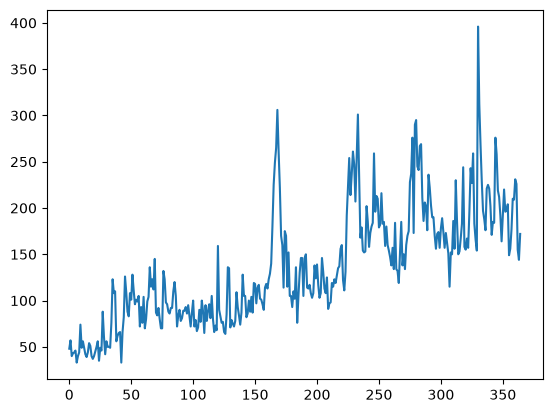

In [201]:
subs.plot()

<Axes: >

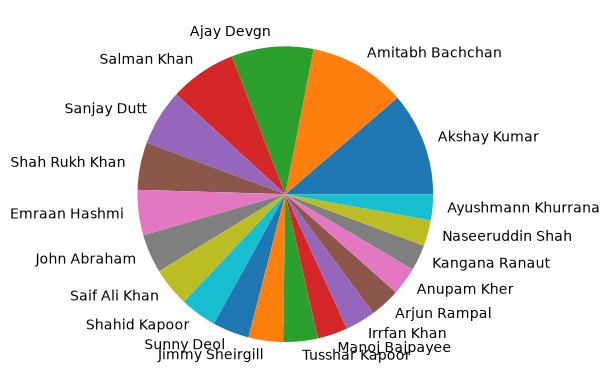

In [202]:
movies.value_counts().head(20).plot(kind='pie')

## SOME IMPORTANT SERIES METHOD

In [203]:
# astype
# between
# clip
# drop_duplicates
# isnull
# dropna
# fillna
# isin
# apply
# copy

In [204]:
subs

0       48
1       57
2       40
3       43
4       44
      ... 
360    231
361    226
362    155
363    144
364    172
Name: subs gained, Length: 365, dtype: int64

In [205]:
movies

movie
Uri: The Surgical Strike                   Vicky Kaushal
Battalion 609                                Vicky Ahuja
The Accidental Prime Minister (film)         Anupam Kher
Why Cheat India                            Emraan Hashmi
Evening Shadows                         Mona Ambegaonkar
                                              ...       
Hum Tumhare Hain Sanam                    Shah Rukh Khan
Aankhen (2002 film)                     Amitabh Bachchan
Saathiya (film)                             Vivek Oberoi
Company (film)                                Ajay Devgn
Awara Paagal Deewana                        Akshay Kumar
Name: lead, Length: 1500, dtype: str

In [206]:
runs

match_no
1       1.0
2      23.0
3      13.0
4      12.0
5       1.0
       ... 
213    73.0
214    25.0
215     7.0
216     NaN
217     NaN
Name: runs, Length: 217, dtype: float64

### .astype()

In [218]:
# .astype
import sys
print("original size of data =",sys.getsizeof(runs))
print("size after compressing using astype =",sys.getsizeof(runs.astype('int16')))


original size of data = 1884
size after compressing using astype = 594


### .between()

In [219]:
# between
runs[runs.between(51,99)].size

43

### .clips()

In [220]:
# whta this will actually do is it will make all the values less than 100 to 100 and greater than 200 to 200
subs.clip(100,200)

0      100
1      100
2      100
3      100
4      100
      ... 
360    200
361    200
362    155
363    144
364    172
Name: subs gained, Length: 365, dtype: int64

### drop_duplicates

In [222]:
# drop_duplicates
temp = pd.Series([1,1,2,2,3,3,4,4])
temp

0    1
1    1
2    2
3    2
4    3
5    3
6    4
7    4
dtype: int64

In [223]:
temp.drop_duplicates(keep='last')

1    1
3    2
5    3
7    4
dtype: int64

In [225]:
temp.drop_duplicates()

0    1
2    2
4    3
6    4
dtype: int64

In [226]:
temp.drop_duplicates().sum()

np.int64(10)

###  MORE FUNCTIONALITY

In [227]:
temp = pd.Series([1,2,3,np.nan,5,6,np.nan,8,np.nan,10])
temp

0     1.0
1     2.0
2     3.0
3     NaN
4     5.0
5     6.0
6     NaN
7     8.0
8     NaN
9    10.0
dtype: float64

In [228]:
temp.size

10

In [229]:
temp.count()

np.int64(7)

In [230]:
# isnull
temp.isnull().sum()

np.int64(3)

In [231]:
# dropna
temp.dropna()

0     1.0
1     2.0
2     3.0
4     5.0
5     6.0
7     8.0
9    10.0
dtype: float64

In [232]:
# fillna
temp.fillna(temp.mean())

0     1.0
1     2.0
2     3.0
3     5.0
4     5.0
5     6.0
6     5.0
7     8.0
8     5.0
9    10.0
dtype: float64

In [234]:
# isin
runs[(runs == 49) | (runs == 99)]

match_no
82    99
86    49
Name: runs, dtype: int64

In [235]:
runs[runs.isin([49,99])]

match_no
82    99
86    49
Name: runs, dtype: int64